# Sampling Simulator Brown Bear

Este notebook se utilizará como plantilla de prueba para los el código en main.r



## Imports
Por defecto importamos dplyr. Los demás paquetes se llamaran individualmente

In [1]:
library(dplyr)
library(data.table)


Attaching package: ‘dplyr’

The following objects are masked from ‘package:stats’:

    filter, lag

The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union

data.table 1.16.2 using 4 threads (see ?getDTthreads).  Latest news: r-datatable.com

Attaching package: ‘data.table’

The following objects are masked from ‘package:dplyr’:

    between, first, last



## Inputs
Los inputs que el usuario debería hacer

In [2]:
TIPO = "MSA" # Tipo de muestra: simple al azar
N = 1000  # tamaño poblacional
n = 10    # tamaño muestral




#Valores por defecto en caso de error
N_POR_DEFECTO = 1000

#Valores por defecto
MEDIANA_INGRESOS = 2800000
MEDIA_INGRESOS = MEDIANA_INGRESOS/ log(2) # calcula la media en base a la mediana de una distribución exponencial. Usa la EPH como fuente
ERROR_INGRESOS = 0.05    # ruido. Error promedio, porcentual, a aplicarse sobre los ingresos

## Funciones

In [ ]:
generar_poblacion = function(N){
  # Genera una matriz con un id hogar y una variable escondida.
  # Inputs:
  # N -- tamaño poblacional
  # Outputs:
  # Matrix Nx3 con las variables id_hogar y var_hidden_1 
  # Manejo de errores:
  # N decimal: trunca (floor())
  # N negativo, cero o NA: utiliza N_POR_DEFECTO
  
  #Validacion
  if(is.na(N) | N < 1  ){
    print("N invalido, pasando a valores por defecto: N = 1000")
    N = N_POR_DEFECTO
  } else if(N > floor(N)){
    print("N debe ser un número entero, se redondea a", floor(N))
    N = floor(N)
  }
  

  output = data.table(
    id_hogar = seq_len(N),
    var_hidden_1 = runif(N)
  )
  return(output)

}

crea_variables = function(matriz){
  # Genera variables manifestas a través de las variables escondidas
  # input una matriz donde al menos una columna tenga el nombre "var_hidden_1"
  # output misma matriz, pero con una columna adicional llamada "ingresos"
  # generación de la variable 'ingresos': se utiliza la distribución exponencial, partiendo de los ingresos medianos por defecto
  # Manejo de errores:
  # si no encuentra 'var_hidden_1' devuelve una columna con la mediana.

  N = nrow(matriz)
  ruido = rnorm( n = N, mean = 1  ,  sd = ERROR_INGRESOS) #error porcentual a la variable ingresos

  if ("var_hidden_1" %in% colnames(matriz)) {
    matriz[, Ingresos :=
      qexp(var_hidden_1, rate = 1/MEDIA_INGRESOS) * ruido
    ]
  } else {
    warning("var_hidden_1 no encontrada, se reemplaza por la media")
    matriz[, Ingresos :=
      MEDIA_INGRESOS * ruido
    ]

  }

  return(matriz)
}


asignar_probabilidad_de_seleccion = function(matriz, n=n, tipo = "MSA"){
  # Añade una columna a matriz que contiene la probabilidad de seleccion n/N
  # inputs:
  # matriz -- matriz que contiene la población
  # n -- tamaño de la muestra
  # tipo -- tipo de muestra, por defecto MSA
  # output:
  # matriz con la población más una columna adicional con la probabilidad de seleccion 'prob_seleccion'
  # Manejo de errores:
  # n menor a uno o mayor a N -- convierte en N
  # n decimal -- trunca (floor())
  # tipo no considerado en la formula -- convierte a MSA
  N = nrow(matriz)
  
  if(n<1){
    print( "n debe ser al menos 1, se convierte a censo n=N")
    n = N
  }
  if(n>N){
    print( "n debe ser a lo sumo igual a N, se convierte a censo n=N")
    n = N
  }
  if(n>floor(n)){
    print("n debe ser un número entero, se trunca")
    n = floor(n)
  }
  if( !(tipo %in% c("MSA") ) ){
    print("tipo de muestreo desconocido, se utilizará muestreo simple al azar")
    tipo = 'MSA'
  }  
  
  matriz[, Prob_seleccion :=
      rep( n/N, times=N)
    ]
  

  return(matriz)



}

seleccionar_muestra = function(matriz, n=n , tipo = "MSA"){
  #Selecciona una muestra simple al azar. La guarda como una columna 'seleccionada' con valor 1 si fue seleccionada y 0 si no.
  # inputs:
  # matriz -- matriz con la poblacion
  # n -- tamaño de la muestra
  # tipo -- tipo de muestreo a utilizar, por defecto MSA
  # Manejo de errores:
  # n mayor a N, n menor a 1 -- se reemplaza por N
  # n decimal -- trunca (floor())
  # tipo no considerado en la formula -- convierte a MSA 
  N = nrow(matriz)
  
  if(n<1){
    print( "n debe ser al menos 1, se convierte a censo n=N")
    n = N
  }
  if(n>N){
    print( "n debe ser a lo sumo igual a N, se convierte a censo n=N")
    n = N
  }
  if(n>floor(n)){
    print("n debe ser un número entero, se trunca")
    n = floor(n)
  }
  if( !(tipo %in% c("MSA") ) ){
    print("tipo de muestreo desconocido, se utilizará muestreo simple al azar")
    tipo = 'MSA'
  } 

  seleccion = sample.int(N, n)


  return(matriz[seleccion,])
}



asignar_no_respuesta = function(matriz, tipo = "MSA", tipo_no_respuesta = 'MCAR', tasa_no_respuesta = 0.0){
  # Crea una columna de ceros y unos, donde 1 representa responde y 0 no responde
  # Inputs:
  # matriz -- muestra o poblacion
  # tipo -- tipo de muestreo, por defecto simple al azar
  # tipo_no_respuesta:  
  #       MCAR -- asigna la respuesta al azar
  #       MAR -- SIN IMPLEMENTAR  asigna la respuesta basandose en un modelo con las variables explicativas
  #       MNAR -- SIN IMPLEMENTAR  asigna la respuesta basandose en la variable respuesta
  # tasa -- proporción de no respuesta
  n = nrow(matriz)
  
 if(tipo_no_respuesta == 'MCAR'){
   responde = 1*(runif(n = n) > tasa_no_respuesta)
   
 }

  matriz[, Responde :=
      responde
    ]
  

  return(matriz)}


ajustar_no_respuesta = function(matriz, tipo = "MSA", tipo_ajuste = 'MCAR'){
  # Crea una columna de ceros y unos, donde 1 representa responde y 0 no responde
  # Inputs:
  # matriz -- muestra o poblacion
  # tipo -- tipo de muestreo, por defecto simple al azar
  # tipo ajuste:  
  #       MCAR -- asume que la no respuesta fue completamente al azar, así que corrige por la tasa de no respuesta
  #       MAR -- SIN IMPLEMENTAR  asigna la respuesta basandose en un modelo con las variables explicativas
  n = nrow(matriz)
  
 if(tipo_ajuste == 'MCAR'){
   tasa_respuesta = sum( matriz$Responde) / n
   
 }

  matriz[, Ajuste_no_respuesta :=
      rep(1/tasa_respuesta)
    ]
  

  return(matriz)}


estimar_total = function(matriz, tipo = "MSA"){
  # Estima el total de ingresos, usando las columnas seleccion y prob_seleccion, es decir el estimador de horvit thompson
  # total = ingresos * seleccion * 1 / prob_seleccion
  # inptus:
  # matriz -- poblacion con las columnas ingreso, prob_seleccion y seleccion
  # tipo -- tipo de muestreo, por defecto MSA
  # outputs
  # estimacion del total
  # Manejo de errores:
  # seleccion debe ser 0 o 1 -- utiliza un censo



  total =sum( matriz$Ingresos * matriz$Responde * matriz$Ajuste_no_respuesta / matriz$Prob_seleccion  )
  return(total)
}





In [17]:
 rpois(5, c(1, 10, 100))

[1]  0 10 91  1 12

In [4]:
N_SIMULACIONES = 10
N=10000000
n=1000
tasa_no_respuesta = 0.3
resultados = matrix(0, nrow=N_SIMULACIONES, ncol=2)
colnames(resultados) = c("estimador", "error")

pob = generar_poblacion(N=N) |> 
  crea_variables() |> 
  asignar_probabilidad_de_seleccion(n=n) 

real = sum(pob$Ingresos)


for(sim in 1:N_SIMULACIONES){
  if(sim %% 10 == 0) {print(sim)}

  muestra = pob |> seleccionar_muestra( n=n) |> asignar_no_respuesta(tasa_no_respuesta = tasa_no_respuesta) |> ajustar_no_respuesta(tipo_ajuste = 'MCAR')

  estimado = estimar_total(muestra)
  error = (estimado - real)/real  

  resultados[sim,"estimador"] = estimado
  resultados[sim,"error"] = error




  




}




[1] 10


In [9]:
c(estimado, real )

[1] 3.900133e+13 4.038911e+13

In [7]:
object.size(muestra)

46200 bytes

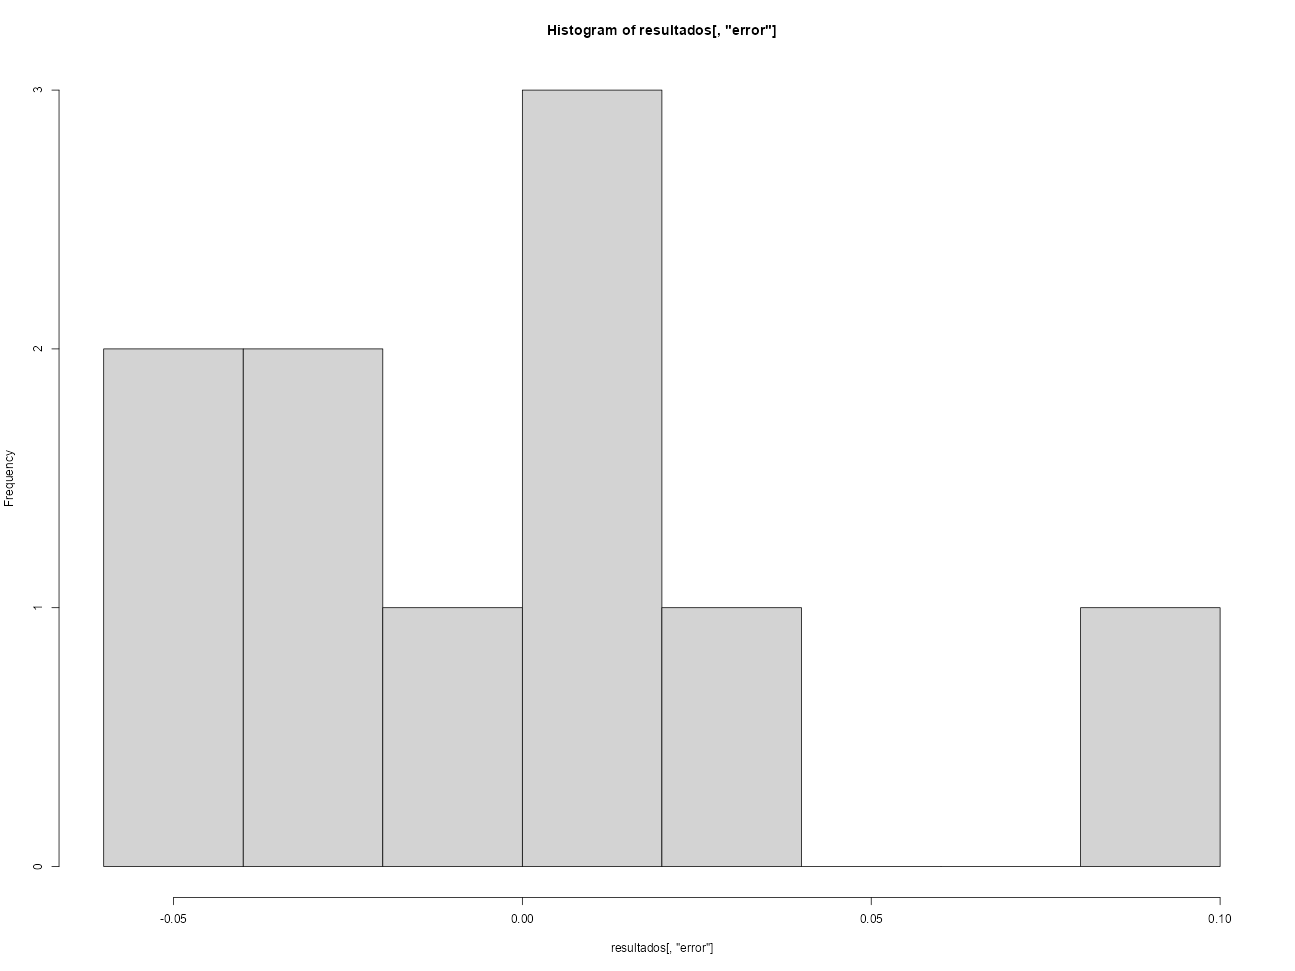

In [5]:
hist(resultados[,"error"])

In [ ]:



var_grupo_edad <- function(v1, v2, media_habitantes,
                                TH = readr::read_csv("TIPO_HOGAR", show_col_types = FALSE)) {
  # Genera tipo de hogar y cantidad de habitantes por grupo de edad
  # Inputs:
  #   v1  -- variable escondida del ingreso (uniforme en [0,1]); se usa para asociar tipo e ingreso
  #   v2  -- variable escondida del tipo de hogar (uniforme en [0,1])
  #   media_habitantes -- esperanza del tamaño del hogar (1 a 10)
  #   TH  -- tabla de tipos (columnas: ninos, adultos, mayores, jefe_adulto), ordenada como anillo
  # Output: lista (ninos 0-14, adultos 15-64, mayores 65-99)

  N <- length(v1)
  K <- nrow(TH)

  # perfiles normalizados por tipo
  tot <- TH$ninos + TH$adultos + TH$mayores
  p_n <- TH$ninos   / tot
  p_a <- TH$adultos / tot
  p_m <- TH$mayores / tot
  p_jefe_adulto <- TH$jefe_adulto            # P(jefe adulto) por tipo

  # cortes aleatorios ordenados, con ancho mínimo amp (anillo = 1e6)
  cortes <- sort( sample.int(1000, K - 1) ) /1000

  # posición en el anillo: v1 mueve el tipo, da la vuelta con %% 1
  b1   <- sample(c(-0.15, -0.10, -0.05, 0.05, 0.10, 0.15), 1)
  x    <- (v2 + b1 * v1)/1e6 %% 1
  tipo <- findInterval(x, c(0, cortes))      # 1..K

  # exceso medio sobre el jefe (el if_else sum 0.1  cuando media_habitantes = 1 )
  lam <- media_habitantes + if_else(media_habitantes == 1, 0.1 , 0)

  # jefe: un único sorteo por hogar
  jefe_adulto <- runif(N) < p_jefe_adulto[tipo]

  ninos   <- rpois(N, lam * p_n[tipo])
  adultos <- rpois(N, lam * p_a[tipo]) + jefe_adulto
  mayores <- rpois(N, lam * p_m[tipo]) + !jefe_adulto

  list(ninos, adultos, mayores)        # el orden debe coincidir con := 
}

  # Crea las variables
  matriz[, Ingresos :=
    var_ingresos(v1=var_hidden_1, v2=var_hidden_2)
  ]
 
  matriz[, , c(Edad_0_14, Edad_15_64, Edad_65_99) :=
     var_grupo_edad(v1 = v1, v2 = v2,
                         media_habitantes = MEDIA_HABITANTES, TH = TH)]


  #elimina las variables escondidas

  matriz[,c("var_hidden_1", "var_hidden_2") := NULL]



  return(matriz)
}
